# **Canny Edge Detection**

In [71]:
from pathlib import Path
import cv2 
import numpy as np
import matplotlib.pyplot as plt

In [72]:

def load_image(url: str = "..\\notebooks\\test_images\\lenna_(test_image).png"):
    """
    This function is simply for loading an image
    """
    image_path = Path(url).resolve()
    
    print(f"Looking for video at: {image_path}")
    
    if not image_path.is_file():
        raise FileNotFoundError(f"Video not found: {image_path}")

    image = cv2.imread(str(image_path))
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

img = load_image()

Looking for video at: C:\Users\Matti\Desktop\Master Courses DTU\Image_Analysis_Micro\DARTS-Dartboard-Automatic-Recognition-Tracking-System\notebooks\test_images\Lenna_(test_image).png


In [73]:
def choose_clahe_grid(frame, tile_size=64):
    """
    Automatically chooses a grid based on the image resolution.

    Each CLAHE tile should cover approximately 64 x 64 pixels.

    The grid dimensions are restricted to odd numbers
    between 5 and 15, making them compatible with
    Gaussian blur kernel requirements.
    """
    h, w = frame.shape[:2]

    grid_x = int(np.clip(round(w / tile_size), 5, 15))
    grid_y = int(np.clip(round(h / tile_size), 5, 15))

    # Ensure both dimensions are odd
    if grid_x % 2 == 0:
        grid_x += 1

    if grid_y % 2 == 0:
        grid_y += 1

    return (grid_x, grid_y)

def choose_clahe_limit(gray):
    """
    Estimate image contrast using the 20th and 80th
    percentiles and adapt the CLAHE clip limit.

    Lower contrast -> higher clip limit
    Higher contrast -> lower clip limit
    """

    p20, p80 = np.percentile(gray, [20, 80])
    contrast = p80 - p20

    clip_limit = np.interp(
        contrast,
        [0, 150],
        [5.0, 1.5]
    )

    return float(clip_limit)

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

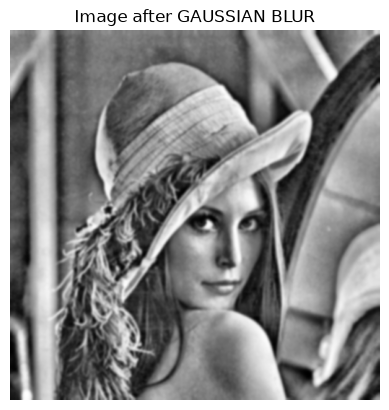

In [74]:
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

clip_limit = choose_clahe_limit(img_gray)
grid_size = choose_clahe_grid(img_gray)

clahe = cv2.createCLAHE(
    clipLimit=clip_limit,
    tileGridSize=grid_size
)

img_clahe = clahe.apply(img_gray)

img_gaus = cv2.GaussianBlur(img_clahe, (0,0) , 1.5)

plt.imshow(img_gaus, cmap = "gray")
plt.title("Image after GAUSSIAN BLUR", fontsize = 12)
plt.axis("off")

## **Edge Detection**

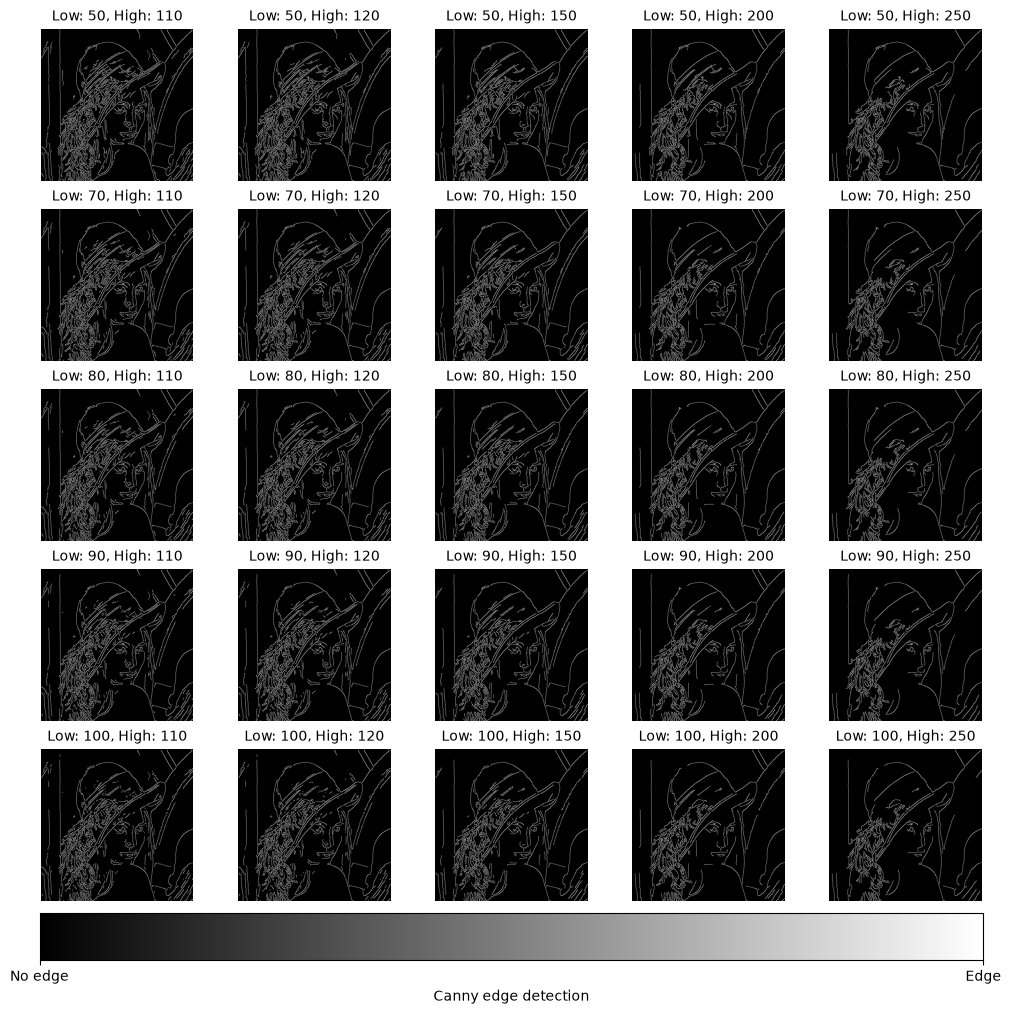

In [75]:
import cv2
import matplotlib.pyplot as plt

low_lim = [50, 70, 80, 90, 100]
up_lim = [110, 120, 150, 200, 250]

fig, axs = plt.subplots(
    5, 5,
    figsize=(10, 10),
    layout="constrained"
)

for row, low in enumerate(low_lim):
    for col, high in enumerate(up_lim):

        frame_edge = cv2.Canny(img_gaus, low, high)

        im = axs[row, col].imshow(
            frame_edge,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axs[row, col].set_title(
            f"Low: {low}, High: {high}",
            fontsize=10
        )
        axs[row, col].axis("off")

cbar = fig.colorbar(
    im,
    ax=axs,
    orientation="horizontal",
    shrink=0.966,
    pad=0.01,
    ticks=[0, 255]
)

cbar.ax.set_xticklabels(["No edge", "Edge"])
cbar.set_label("Canny edge detection")

plt.show()

In [76]:
def choose_canny_thresholds(gray):
    """
    Automatically chooses Canny thresholds based on
    the distribution of gradient magnitudes.
    """

    # Calculate image gradients
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

    # Calculate gradient magnitude
    magnitude = cv2.magnitude(gx, gy)

    # Exclude zero gradients
    gradients = magnitude[magnitude > 0]

    if gradients.size == 0:
        return 0, 0

    # Determine thresholds
    upper = float(np.percentile(gradients, 90))
    lower = 0.3 * upper

    return lower, upper

Lower threshold: 39.3
Upper threshold: 131.0


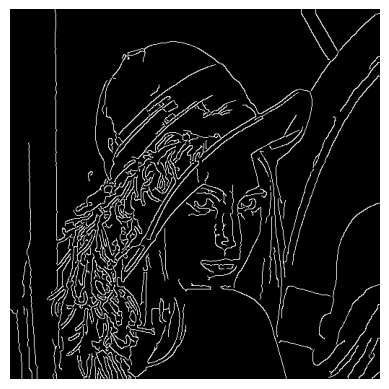

In [77]:
lower, upper = choose_canny_thresholds(img_gaus)

frame_edge = cv2.Canny(
    img_gaus,
    lower,
    upper,
    L2gradient=True
)

print(f"Lower threshold: {lower:.1f}")
print(f"Upper threshold: {upper:.1f}")

plt.imshow(frame_edge, cmap="gray")
plt.axis("off")
plt.show()

# **Video Testing**

In [78]:
import cv2
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def get_training_video(url: str = r"..\data\videos\black_background_noHuman.mp4"):
    """
    Loads a training video from a file location.

    Args:
        url: File location

    Returns:
        cv2.VideoCapture object
    """

    video_path = Path(url).resolve()

    print(f"Looking for video at: {video_path}")

    if not video_path.is_file():
        raise FileNotFoundError(f"Video not found: {video_path}")

    video = cv2.VideoCapture(str(video_path))

    if not video.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    fps = video.get(cv2.CAP_PROP_FPS)
    total_frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

    print(f"FPS: {fps}")
    print(f"Total frames: {total_frames}")
    print(f"Total video length: {round(total_frames/fps,2)} seconds")

    return video

In [86]:
import cv2
import numpy as np

video_path1 = r"..\data\videos\black_background_yesHuman.mp4"
video_path2 = r"..\data\videos\white_background_yesHuman.mp4"
video_path3 = r"..\data\videos\wood_background_yesHuman.mp4"

videos = [
    get_training_video(video_path1),
    get_training_video(video_path2),
    get_training_video(video_path3)
]


try:
    while True:
        frames = []
        for i, video in enumerate(videos):
            ret, frame = video.read()

            if not ret:
                break

            img_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

            # Perform CLAHE
            clip_limit = choose_clahe_limit(img_gray)
            grid_size = choose_clahe_grid(img_gray)

            clahe = cv2.createCLAHE(
                clipLimit=clip_limit,
                tileGridSize=grid_size
            )
            img_clahe = clahe.apply(img_gray)
            # Gaussian Blur
            img_gaus = cv2.GaussianBlur(img_clahe, (0,0) , 3)

            #Perform canny edges
            lower, upper = choose_canny_thresholds(img_gaus)
            
            frame_edge = cv2.Canny(
                img_gaus,
                lower,
                upper,
                L2gradient=True
            )

            processed = cv2.resize(frame_edge, (480, 270))
            frames.append(processed)

        if len(frames) != len(videos):
            break

        for i, frame in enumerate(frames):
            name = f"Video {i+1}"
            cv2.imshow(name, frame)
            cv2.moveWindow(name, i * 500, 100)

        if cv2.waitKey(33) & 0xFF == ord('q'):
            break

finally:
    for video in videos:
        video.release()

    cv2.destroyAllWindows()

Looking for video at: C:\Users\Matti\Desktop\Master Courses DTU\Image_Analysis_Micro\DARTS-Dartboard-Automatic-Recognition-Tracking-System\data\videos\black_background_yesHuman.mp4
FPS: 29.974798258788788
Total frames: 471.0
Total video length: 15.71 seconds
Looking for video at: C:\Users\Matti\Desktop\Master Courses DTU\Image_Analysis_Micro\DARTS-Dartboard-Automatic-Recognition-Tracking-System\data\videos\white_background_yesHuman.mp4
FPS: 29.97700915823034
Total frames: 472.0
Total video length: 15.75 seconds
Looking for video at: C:\Users\Matti\Desktop\Master Courses DTU\Image_Analysis_Micro\DARTS-Dartboard-Automatic-Recognition-Tracking-System\data\videos\wood_background_yesHuman.mp4
FPS: 29.985681983553842
Total frames: 511.0
Total video length: 17.04 seconds
